In [1]:
!pip -q install shap

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")

In [3]:
uploaded = files.upload()

file_name = next(iter(uploaded))

if file_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_name)
else:
    df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Missing values:
cus

In [5]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Convert TotalCharges to numeric if present
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"], errors="coerce"
    )

# Remove accidental spaces from text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Remove rows where the target is missing
df = df.dropna(subset=["Churn"])

print("Cleaned dataset shape:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

Cleaned dataset shape: (7043, 21)

Missing values after cleaning:
TotalCharges      11
gender             0
SeniorCitizen      0
Partner            0
customerID         0
Dependents         0
tenure             0
MultipleLines      0
PhoneService       0
OnlineSecurity     0
dtype: int64


In [6]:
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


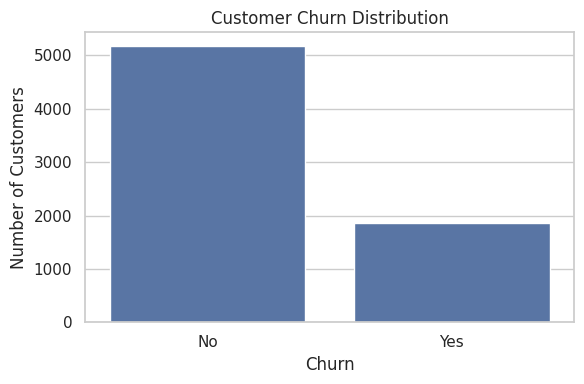

In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

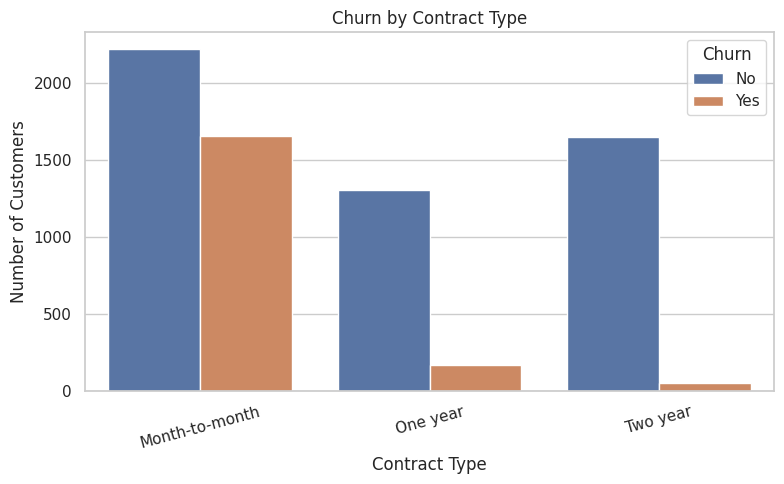

In [8]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

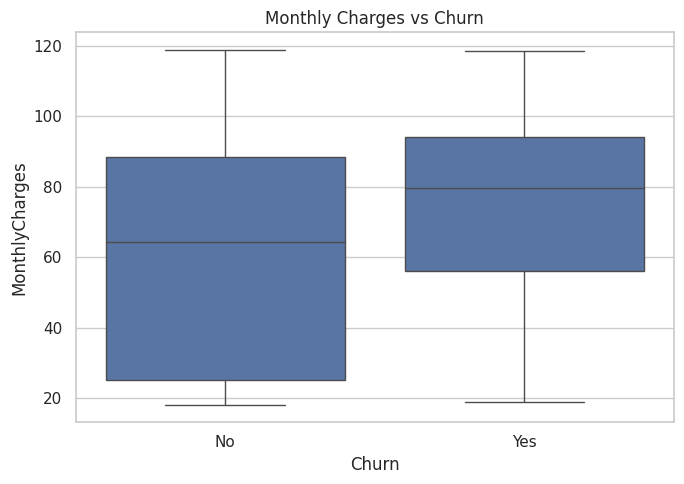

In [9]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.tight_layout()
plt.show()

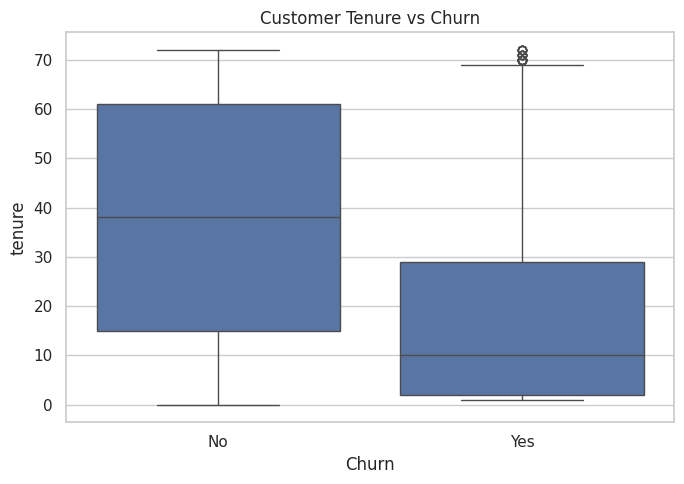

In [10]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure vs Churn")
plt.tight_layout()
plt.show()

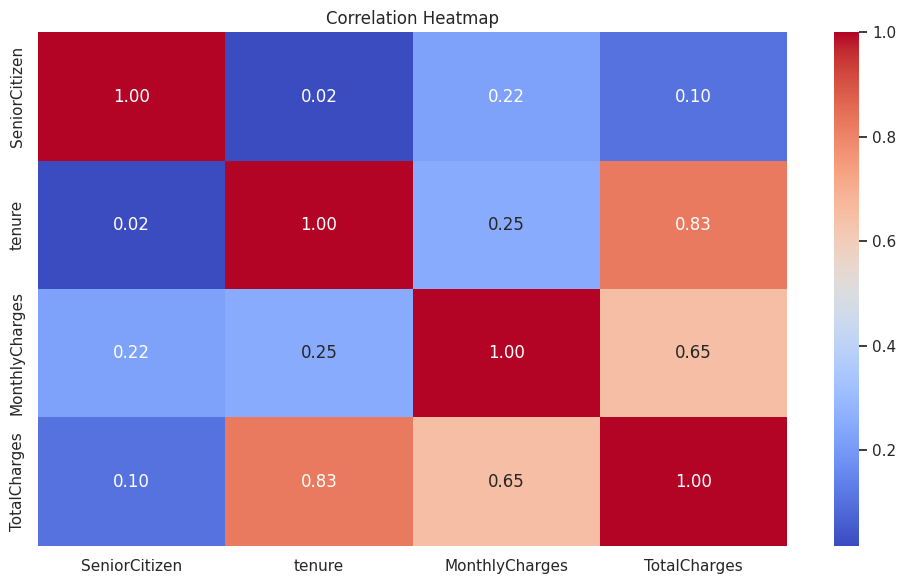

In [11]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [12]:
df_model = df.copy()

# Remove ID column if it exists
if "customerID" in df_model.columns:
    df_model = df_model.drop(columns=["customerID"])

# Separate target and features
X = df_model.drop(columns=["Churn"])
y = df_model["Churn"].map({"No": 0, "Yes": 1})

# Remove rows with an unrecognized target value, if any
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid].astype(int)

print("Features:", X.shape)
print("Target:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features: (7043, 19)
Target: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 5634
Testing records: 1409


In [14]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [15]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1 Score:", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

Accuracy: 0.738
Precision: 0.504
Recall: 0.783
F1 Score: 0.614
ROC-AUC: 0.841

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



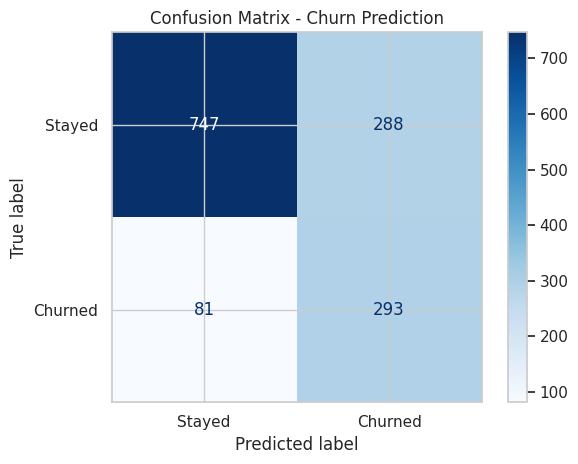

In [16]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Churn Prediction")
plt.tight_layout()
plt.show()

tenure             0.149474
Contract           0.034137
MonthlyCharges     0.032305
InternetService    0.028561
OnlineSecurity     0.003753
PaymentMethod      0.003345
MultipleLines      0.001099
TotalCharges       0.000907
gender            -0.000195
SeniorCitizen     -0.000259
Partner           -0.000323
StreamingMovies   -0.000339
TechSupport       -0.000666
PhoneService      -0.001547
Dependents        -0.001643
dtype: float64


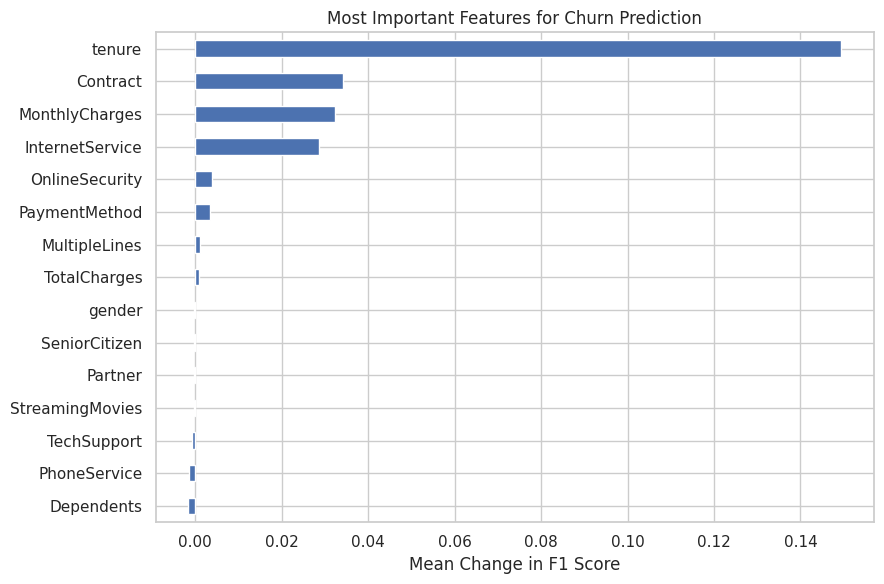

In [17]:
result = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance = pd.Series(
    result.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

print(importance.head(15))

importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Most Important Features for Churn Prediction")
plt.xlabel("Mean Change in F1 Score")
plt.tight_layout()
plt.show()

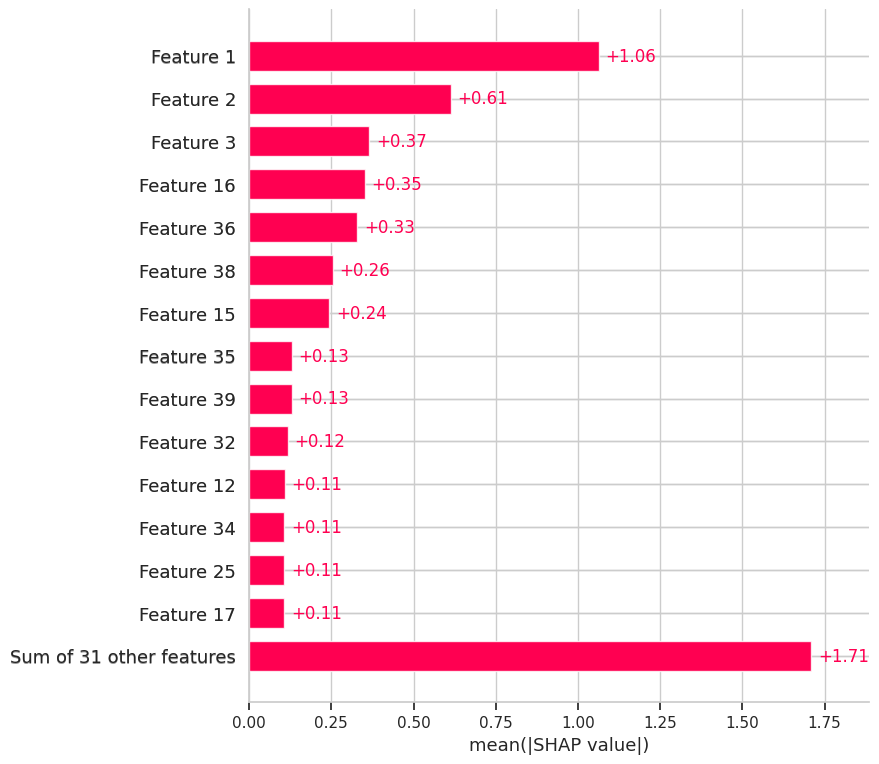

In [18]:
import shap

# Transform the data using the fitted preprocessing pipeline
preprocessor_fitted = model.named_steps["preprocessor"]

X_train_transformed = preprocessor_fitted.transform(X_train)
X_test_transformed = preprocessor_fitted.transform(X_test)

feature_names = preprocessor_fitted.get_feature_names_out()

# Explain the Logistic Regression classifier
classifier = model.named_steps["classifier"]

explainer = shap.LinearExplainer(
    classifier,
    X_train_transformed
)

shap_values = explainer(X_test_transformed[:100])

shap.plots.bar(shap_values, max_display=15)

In [19]:
all_probabilities = model.predict_proba(X)[:, 1]

results = df.loc[X.index].copy()

results["Churn_Probability"] = all_probabilities

results["Risk_Category"] = pd.cut(
    results["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.0],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

results["Predicted_Churn"] = np.where(
    results["Churn_Probability"] >= 0.50,
    "Yes",
    "No"
)

display(
    results[
        ["Churn", "Churn_Probability",
         "Predicted_Churn", "Risk_Category"]
    ].head(10)
)

,Churn,Churn_Probability,Predicted_Churn,Risk_Category
0,No,0.802138,Yes,High Risk
1,No,0.118952,No,Low Risk
2,Yes,0.531901,Yes,Medium Risk
3,No,0.081651,No,Low Risk
4,Yes,0.854034,Yes,High Risk
5,Yes,0.909209,Yes,High Risk
6,No,0.720264,Yes,High Risk
7,No,0.522654,Yes,Medium Risk
8,Yes,0.816855,Yes,High Risk
9,No,0.033943,No,Low Risk


In [20]:
results.to_csv(
    "customer_churn_risk_predictions.csv",
    index=False
)

files.download("customer_churn_risk_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
if "Contract" in df.columns:
    contract_analysis = (
        df.groupby("Contract", observed=True)["Churn"]
        .apply(lambda s: (s == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    print("Churn rate by contract (%):")
    print(contract_analysis.round(2))

if "InternetService" in df.columns:
    internet_analysis = (
        df.groupby("InternetService", observed=True)["Churn"]
        .apply(lambda s: (s == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    print("\nChurn rate by internet service (%):")
    print(internet_analysis.round(2))

Churn rate by contract (%):
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Churn rate by internet service (%):
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64
